# 28. Error audit: the clips every model gets wrong

Notebook 16 counted how many of the four models get each test clip right; about 18% (141 clips) are wrong in all four. This notebook **shows** those clips so they
can be checked by eye: is the label right, is the right player tracked, is the hit inside the clip, is the clip long enough to contain a shot?

**What is shown for each clip.** The true label; each model's majority prediction over its three reporting seeds (with ST-GCN's confidence); the number of real
frames; whether it is from a drill session; and a filmstrip of 6 of the 30 frames with the tracked skeleton and a box. If the source video is found the skeleton is drawn
on the real frames, otherwise on a blank canvas. Frames are cropped to the region the player moves through over the whole clip.

**About the box.** The extraction log keeps no per frame tracker boxes, so the box is drawn **from the keypoints** (extent of joints with confidence above 0.3, plus a margin). It shows where the skeleton is,
not the tracker's own box. If a box sits on the wrong player, the keypoints are on the wrong player.

**About the video.** The notebook indexes video files by name under `BADMINTON_VIDEOS` (default: the data folder). If none is found it still runs on skeletons alone; set the variable to the folder holding the source clips to get the real frames.
Frames are mapped by position (frame t of 30 to the same fraction of the source clip), which is approximate when a clip was resampled.

**Test set use.** This is inspection of the test predictions already made, not selection: nothing found here should be used to tune a model on the test set. Findings about labels and clips are
reported as an error analysis; any fix (relabelling, a noise robust loss) would be decided on validation.

In [1]:
import glob
import os
import re
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from clearml import Task

try:
    import cv2
except ImportError:
    cv2 = None

REPO = os.environ.get("BADMINTON_REPO", "/workspace/badminton-honours-project")
DATA = os.environ.get("BADMINTON_DATA", "/workspace/data")
OUTPUTS = os.environ.get("BADMINTON_OUTPUTS", "/workspace/outputs")
VIDEO_ROOT = os.environ.get("BADMINTON_VIDEOS", DATA)
EXPORT = f"{OUTPUTS}/results"
os.makedirs(EXPORT, exist_ok=True)
sys.path.insert(0, REPO)
import dataset as ds

MODELS = ["stgcn", "lstm", "transformer", "sttr"]
LABEL = {"stgcn": "ST-GCN", "lstm": "LSTM", "transformer": "Transformer", "sttr": "ST-TR"}
HEADLINE = "advanced"
RUN_RE = re.compile(r"^(stgcn|lstm|transformer|sttr)_(advanced|none)_s(\d+)$")
DRILL_SESSION = "2023-05-02"
CONF_MIN = 0.3
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.spines.top": False, "axes.spines.right": False})

task = Task.init(project_name="BadmintonPoseAnalysis/results", task_name="error_audit", task_type=Task.TaskTypes.qc,
                 tags=["analysis", "error_audit"], reuse_last_task_id=False, auto_connect_frameworks={"matplotlib": False})
logger = task.get_logger()

ClearML Task: created new task id=6bd27a310fc749f4a94ae0b401110c1a
2026-10-08 09:36:05,049 - clearml.Repository Detection - WARNING - Failed accessing the jupyter server(s): []
ClearML results page: https://app.clear.ml/projects/b58b0baede1f4527b9f5e9bdceb07833/tasks/6bd27a310fc749f4a94ae0b401110c1a/output/log
ClearML Monitor: Could not detect iteration reporting, falling back to iterations as seconds-from-start


In [2]:
manifest = ds.load_filtered_manifest(f"{DATA}/split_manifest.csv", f"{DATA}/extraction_log.csv",
                                     f"{DATA}/keypoints_interp_log.csv", min_native_frames=5)
class_names = sorted(manifest["class_name"].unique())
K = len(class_names)
short = [c.split("_", 1)[1] for c in class_names]
cid = {c: i for i, c in enumerate(class_names)}
extraction = pd.read_csv(f"{DATA}/extraction_log.csv").set_index("filepath")
repair = pd.read_csv(f"{DATA}/keypoints_interp_log.csv").set_index("filepath")
class_of = manifest.set_index("filepath")["class_name"]

rows = []
for p in glob.glob(f"{OUTPUTS}/models/**/*_predictions.csv", recursive=True):
    m = RUN_RE.match(os.path.basename(p).replace("_predictions.csv", ""))
    if m and m.group(2) == HEADLINE:
        d = pd.read_csv(p)
        d = d[d["split"] == "test"][["filepath", "label", "pred", "confidence"]].copy()
        d["model"], d["seed"] = m.group(1), int(m.group(3))
        rows.append(d)
long = pd.concat(rows, ignore_index=True)
long["correct"] = long["label"] == long["pred"]
print(long.groupby("model")["seed"].nunique().to_dict(), "seeds per model;", long["filepath"].nunique(), "test clips")

manual review: dropped 4 clips
short clip rule: dropped 4 train clips with fewer than 5 real frames
7810 clips remain (train 6247, test 782, val 781)
{'lstm': 3, 'stgcn': 3, 'sttr': 3, 'transformer': 3} seeds per model; 782 test clips


## Which clips, and how sure

A clip is **wrong for a model** when fewer than half of that model's seeds get it right (the notebook 16 rule). **All four wrong** clips are the audit set.
Two further columns rank them: how many of the 12 runs (4 models x 3 seeds) predict the *same* wrong class, and ST-GCN's mean confidence in that class. A clip that all 12 runs call the same wrong class with high confidence is the strongest
candidate for a label problem; scattered predictions with low confidence look more like genuinely ambiguous clips.

In [3]:
per_model = long.groupby(["filepath", "model"])["correct"].mean().unstack()
wrong = per_model < 0.5
all_wrong = wrong.all(axis=1)
true_label = long.groupby("filepath")["label"].first()

modal = (long.groupby(["filepath", "model"])["pred"].agg(lambda s: s.value_counts().index[0]).unstack())
wrong_runs = long[~long["correct"]]
top_wrong = wrong_runs.groupby("filepath")["pred"].agg(lambda s: s.value_counts().index[0])
top_wrong_share = wrong_runs.groupby("filepath")["pred"].agg(lambda s: s.value_counts().iloc[0]) / long.groupby("filepath").size()
st_conf = (long[(long["model"] == "stgcn")].merge(top_wrong.rename("top_wrong"), left_on="filepath", right_index=True)
           .query("pred == top_wrong").groupby("filepath")["confidence"].mean())

audit = pd.DataFrame({"true": true_label.map(lambda c: c.split("_", 1)[1]),
                      **{LABEL[m]: modal[m].map(lambda c: c.split("_", 1)[1]) for m in MODELS}})
audit["models wrong"] = wrong.sum(axis=1)
audit["same wrong class, share of 12 runs"] = top_wrong_share.reindex(audit.index).fillna(0).round(2)
audit["most common wrong class"] = top_wrong.reindex(audit.index).map(lambda c: c.split("_", 1)[1] if isinstance(c, str) else "")
audit["ST-GCN confidence in it"] = st_conf.reindex(audit.index).round(2)
audit["real frames"] = repair["n_native"].reindex(audit.index)
audit["clip frames"] = extraction["num_frames_total"].reindex(audit.index)
audit["source"] = ["drill session" if DRILL_SESSION in fp else "match" for fp in audit.index]
audit["suspect score"] = (audit["same wrong class, share of 12 runs"] * audit["ST-GCN confidence in it"].fillna(0)).round(3)

audit_set = audit[all_wrong.reindex(audit.index)].sort_values("suspect score", ascending=False)
print(f"{len(audit_set)} of {len(audit)} test clips are wrong in all four models ({100 * len(audit_set) / len(audit):.1f}%)")
audit_set.head(20)

141 of 782 test clips are wrong in all four models (18.0%)


,true,ST-GCN,LSTM,Transformer,ST-TR,models wrong,"same wrong class, share of 12 runs",most common wrong class,ST-GCN confidence in it,real frames,clip frames,source,suspect score
filepath,,,,,,,,,,,,,
03_Tap Smash/2022-08-30_18-27-08_dataset_set1_086_007140_007162_B_03.mp4,Tap Smash,Smash,Smash,Smash,Smash,4,1.00,Smash,0.98,22,22,match,0.980
01_Cross Court Flight/2022-08-31_18-59-49_dataset_set1_139_011816_011841_A_01.mp4,Cross Court Flight,Cut,Cut,Cut,Cut,4,1.00,Cut,0.97,25,25,match,0.970
06_Push Shot/2022-08-30_19-10-16_dataset_set1_087_006723_006760_A_06.mp4,Push Shot,Lift,Lift,Lift,Lift,4,1.00,Lift,0.94,30,37,match,0.940
15_Flat Shot/2022-09-07_19-42-57_dataset_set1_130_011282_011324_A_15.mp4,Flat Shot,Lift,Lift,Lift,Lift,4,1.00,Lift,0.94,30,42,match,0.940
12_Clear/2022-08-31_18-27-01_dataset_set1_066_006370_006401_A_12.mp4,Clear,Transitional Slice,Transitional Slice,Transitional Slice,Transitional Slice,4,1.00,Transitional Slice,0.91,30,31,match,0.910
08_Cut/2022-09-07_19-11-05_dataset_set1_149_014132_014158_A_08.mp4,Cut,Drop Shot,Drop Shot,Drop Shot,Drop Shot,4,1.00,Drop Shot,0.90,26,26,match,0.900
03_Tap Smash/2022-08-30_18-27-08_dataset_set1_139_010716_010727_A_03.mp4,Tap Smash,Smash,Smash,Smash,Smash,4,0.92,Smash,0.97,11,11,match,0.892
14_Smash/2022-09-06_19-58-59_dataset_set1_156_012438_012488_B_14.mp4,Smash,Long Serve,Long Serve,Long Serve,Long Serve,4,1.00,Long Serve,0.88,30,50,match,0.880
15_Flat Shot/2022-09-07_20-06-13_dataset_set1_020_002003_002017_A_15.mp4,Flat Shot,Smash,Smash,Smash,Smash,4,1.00,Smash,0.87,14,14,match,0.870


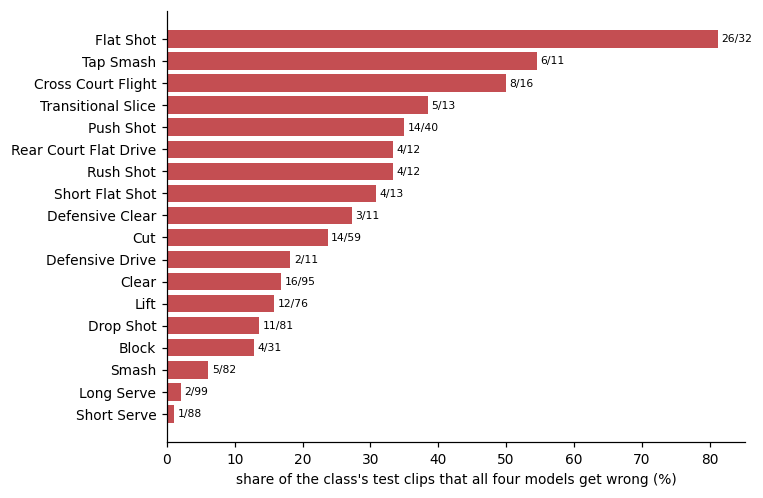

,true,most common wrong class,clips
56,Push Shot,Lift,8
42,Flat Shot,Lift,8
50,Lift,Push Shot,6
40,Flat Shot,Cut,5
75,Tap Smash,Smash,5
8,Clear,Lift,5
45,Flat Shot,Smash,4
14,Cross Court Flight,Cut,4
49,Lift,Drop Shot,4
43,Flat Shot,Push Shot,3


In [4]:
by_class = pd.DataFrame({"all four wrong": audit_set["true"].value_counts(),
                         "test clips": audit["true"].value_counts()}).fillna(0).astype(int)
by_class["share wrong (%)"] = (100 * by_class["all four wrong"] / by_class["test clips"]).round(1)
by_class = by_class.sort_values("all four wrong", ascending=False)

pairs = (audit_set.groupby(["true", "most common wrong class"]).size().rename("clips").reset_index()
         .sort_values("clips", ascending=False).head(12))

logger.report_table("all four wrong, by true class", "error_audit", iteration=0, table_plot=by_class.reset_index().rename(columns={"index": "class"}))
logger.report_table("all four wrong, most common confusions", "error_audit", iteration=0, table_plot=pairs)

fig, ax = plt.subplots(figsize=(7, 4.6))
d = by_class.sort_values("share wrong (%)")
ax.barh(d.index, d["share wrong (%)"], color="#c44e52")
for y, (n, t) in enumerate(zip(d["all four wrong"], d["test clips"])):
    ax.text(d["share wrong (%)"].iloc[y] + 0.5, y, f"{n}/{t}", va="center", fontsize=7)
ax.set_xlabel("share of the class's test clips that all four models get wrong (%)")
fig.tight_layout()
logger.report_matplotlib_figure("wrong in all four, by class", "error_audit", figure=fig, iteration=0, report_interactive=False)
plt.show()
pairs

## Properties of the audit set against the other test clips

Short clips (few real frames), drill session clips and the share of the clip the hitting wrist is visible give a first idea of whether the audit set is mostly "bad clips" or "hard but fine clips".

In [5]:
def hit_wrist_conf(fp):
    stem = os.path.splitext(os.path.basename(fp))[0]
    a = np.load(f"{DATA}/keypoints_interp/{class_of[fp]}/{stem}.npy")
    travel = [np.linalg.norm(np.diff(a[:, j, :2], axis=0), axis=1).sum() for j in (9, 10)]
    return a[:, 9 + int(np.argmax(travel)), 2].mean()


audit["hitting wrist confidence"] = [hit_wrist_conf(fp) for fp in audit.index]
audit["in audit set"] = all_wrong.reindex(audit.index)
summary = audit.groupby("in audit set").agg(clips=("true", "size"), median_real_frames=("real frames", "median"),
                                           under_10_real_frames=("real frames", lambda s: int((s < 10).sum())),
                                           drill_share=("source", lambda s: round((s == "drill session").mean(), 3)),
                                           median_wrist_confidence=("hitting wrist confidence", "median")).round(3)
logger.report_table("audit set vs other test clips", "error_audit", iteration=0, table_plot=summary.reset_index())
summary

,clips,median_real_frames,under_10_real_frames,drill_share,median_wrist_confidence
in audit set,,,,,
False,641,30.0,2,0.053,0.611
True,141,29.0,4,0.035,0.606


## Looking at the clips

`show_clip` draws one clip; `gallery` pages through a list. Skeleton colours: confident joints as dots, bones where both ends are above 0.3 confidence, box from the visible keypoints.

In [6]:
def index_videos(root, exts=(".mp4", ".avi", ".mov", ".mkv")):
    found = {}
    for d, _, files in os.walk(root):
        for f in files:
            if f.lower().endswith(exts):
                found.setdefault(os.path.splitext(f)[0], os.path.join(d, f))
    return found


VIDEOS = index_videos(VIDEO_ROOT)
stems_needed = {os.path.splitext(os.path.basename(fp))[0] for fp in audit_set.index}
print(f"{len(VIDEOS)} video files under {VIDEO_ROOT}; {len(stems_needed & set(VIDEOS))} of the {len(stems_needed)} audit clips found"
      + ("" if cv2 else "; opencv not installed, skeleton only"))
if not (stems_needed & set(VIDEOS)):
    print("no source video found for the audit set: set BADMINTON_VIDEOS to the folder with the source clips to draw on real frames")


def load_kp(fp):
    return np.load(f"{DATA}/keypoints_interp/{class_of[fp]}/{os.path.splitext(os.path.basename(fp))[0]}.npy")


def show_clip(fp, frames=(0, 6, 12, 18, 24, 29)):
    row = audit.loc[fp]
    kp = load_kp(fp)
    stem = os.path.splitext(os.path.basename(fp))[0]
    video = VIDEOS.get(stem) if cv2 else None
    cap = cv2.VideoCapture(video) if video else None
    n_total = int(row["clip frames"])

    seen = kp[kp[:, :, 2] > CONF_MIN][:, :2]
    lo, hi = seen.min(axis=0), seen.max(axis=0)
    # one window for the whole clip: the region the player moves through, so motion is visible across the strip
    allx = kp[:, :, 0][kp[:, :, 2] > CONF_MIN]
    ally = kp[:, :, 1][kp[:, :, 2] > CONF_MIN]
    mx, my = 0.15 * (allx.max() - allx.min()), 0.15 * (ally.max() - ally.min())
    xlim, ylim = (allx.min() - mx, allx.max() + mx), (ally.max() + my, ally.min() - my)

    fig, axes = plt.subplots(1, len(frames), figsize=(2.3 * len(frames), 3.2))
    for ax, t in zip(axes, frames):
        img = None
        if cap is not None and n_total > 0:
            cap.set(cv2.CAP_PROP_POS_FRAMES, int(round(t / 29 * (n_total - 1))))
            ok, bgr = cap.read()
            img = bgr[..., ::-1] if ok else None
        if img is not None:
            ax.imshow(img)
        pts = kp[t]
        vis = pts[:, 2] > CONF_MIN
        for a, b in ds.COCO_SKELETON:
            if vis[a] and vis[b]:
                ax.plot([pts[a, 0], pts[b, 0]], [pts[a, 1], pts[b, 1]], color="#55a868", lw=1.4)
        ax.scatter(pts[vis, 0], pts[vis, 1], s=7, color="#c44e52", zorder=3)
        if vis.sum() >= 3:
            x0, y0 = pts[vis, :2].min(axis=0)
            x1, y1 = pts[vis, :2].max(axis=0)
            pad = 0.08 * max(x1 - x0, y1 - y0)
            ax.add_patch(Rectangle((x0 - pad, y0 - pad), x1 - x0 + 2 * pad, y1 - y0 + 2 * pad, fill=False, ec="#dd8452", lw=1.2))
        ax.set_xlim(*xlim)
        ax.set_ylim(*ylim)
        ax.set_aspect("equal")
        ax.axis("off")
        ax.set_title(f"frame {t}", fontsize=7)
    if cap is not None:
        cap.release()
    preds = "  ".join(f"{LABEL[m]}: {row[LABEL[m]]}" for m in MODELS)
    fig.suptitle(f"TRUE: {row['true']}   |   {preds}\n{stem}   real frames {row['real frames']}   {row['source']}   "
                 f"same wrong class in {row['same wrong class, share of 12 runs']:.0%} of runs ({row['most common wrong class']}, "
                 f"ST-GCN conf {row['ST-GCN confidence in it']})   [{'video' if video else 'skeleton only'}]", fontsize=8, y=1.08)
    plt.show()


def gallery(frame, n=8, start=0):
    for fp in frame.index[start:start + n]:
        show_clip(fp)

0 video files under /workspace/data; 0 of the 141 audit clips found
no source video found for the audit set: set BADMINTON_VIDEOS to the folder with the source clips to draw on real frames


### Strongest label suspects

All four models wrong, the same wrong class in most of the 12 runs, and high ST-GCN confidence. Check each against the video: is the shot really the labelled one?

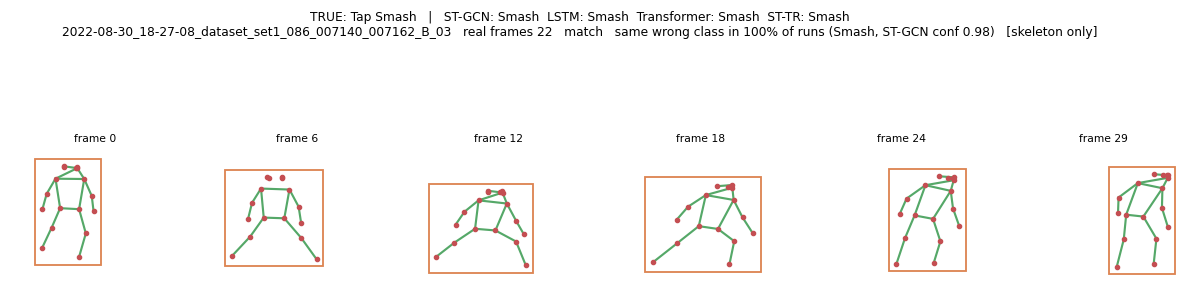

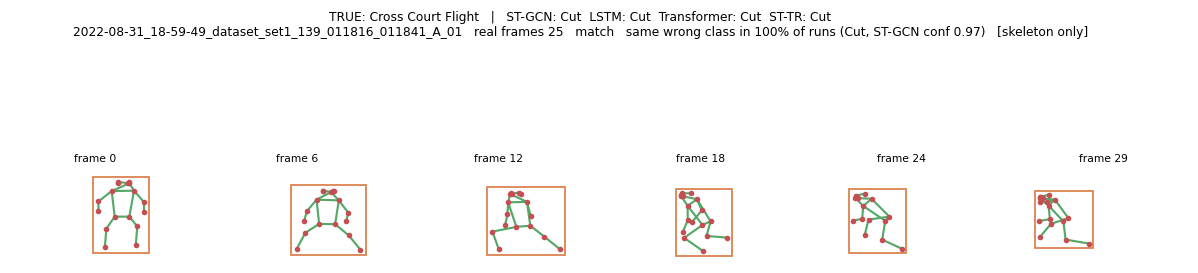

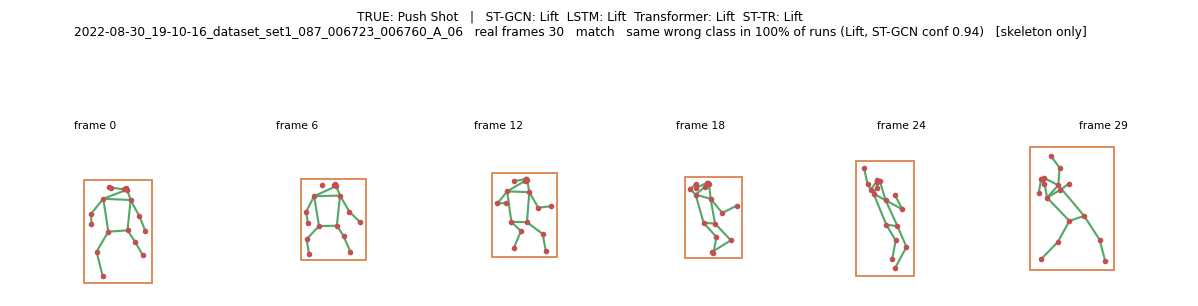

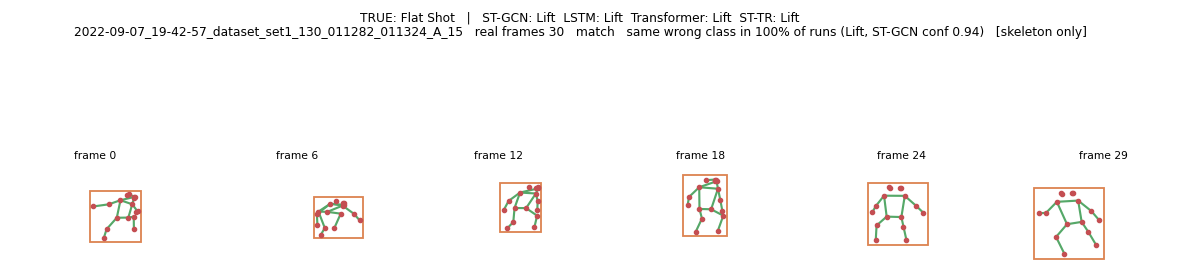

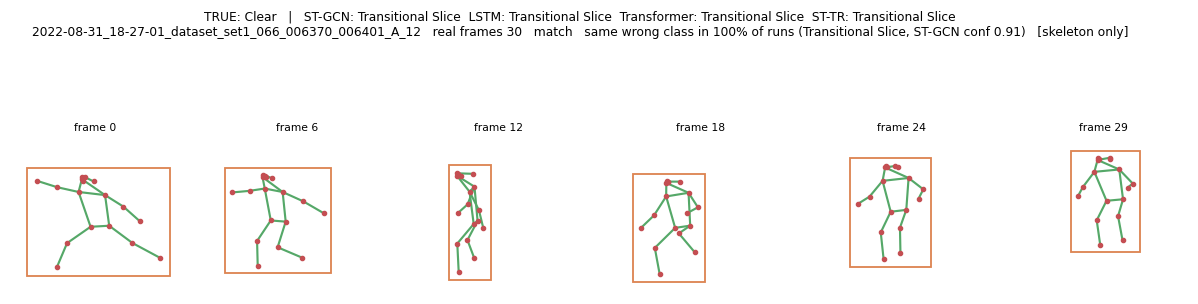

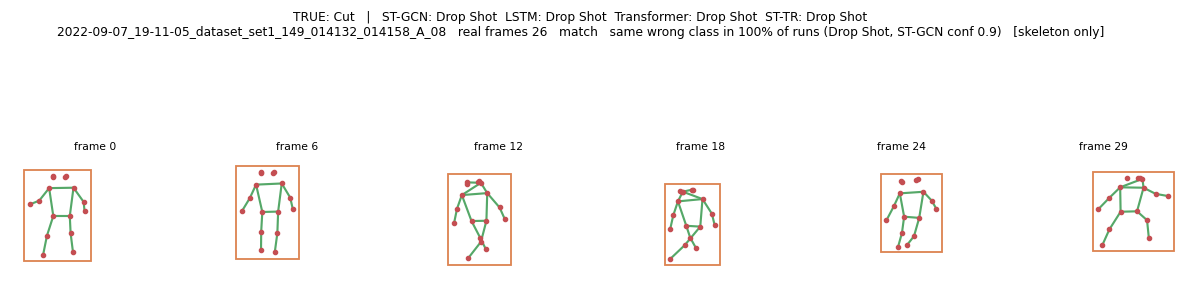

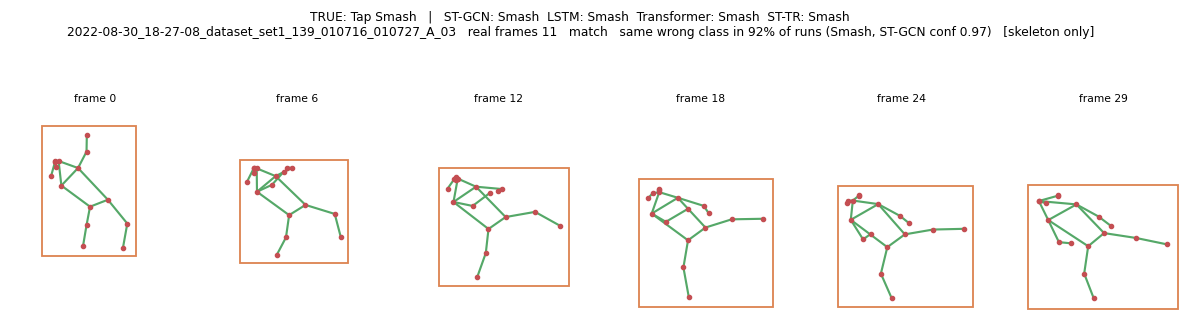

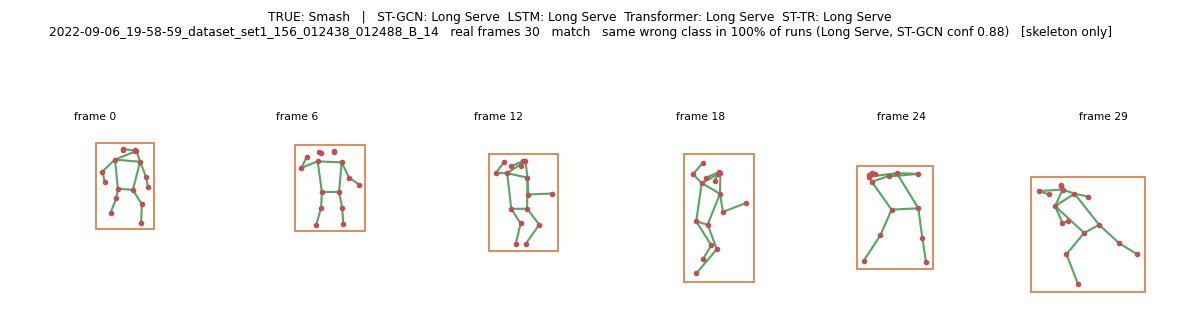

In [7]:
gallery(audit_set, n=8)

### The next ones (change `start` to page)

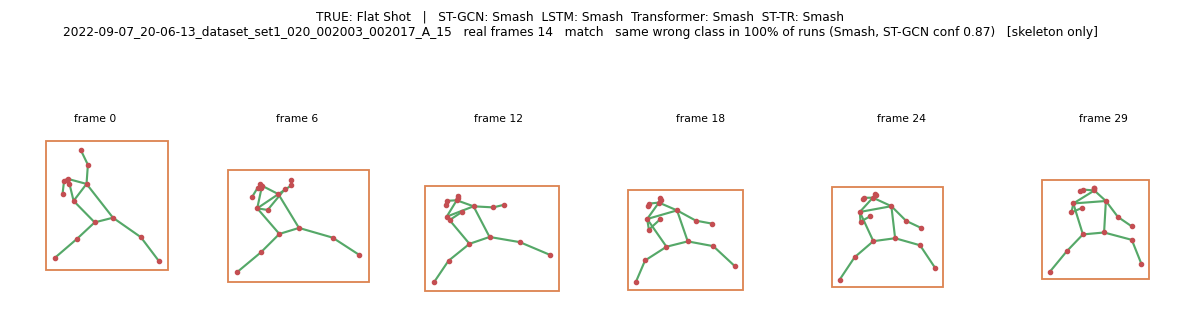

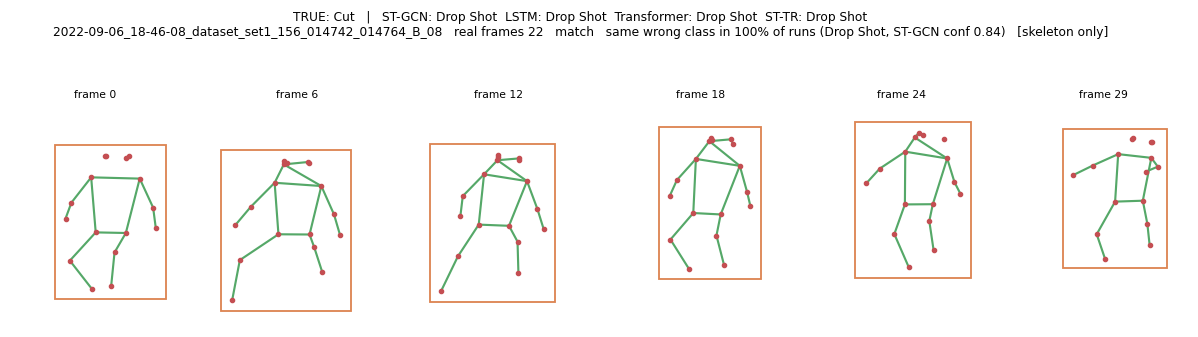

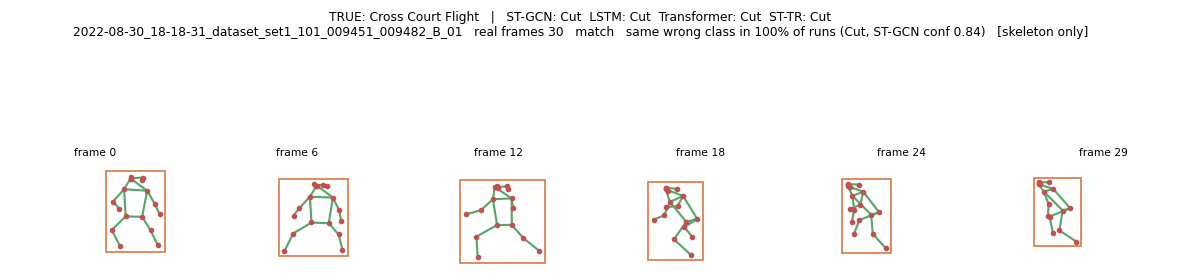

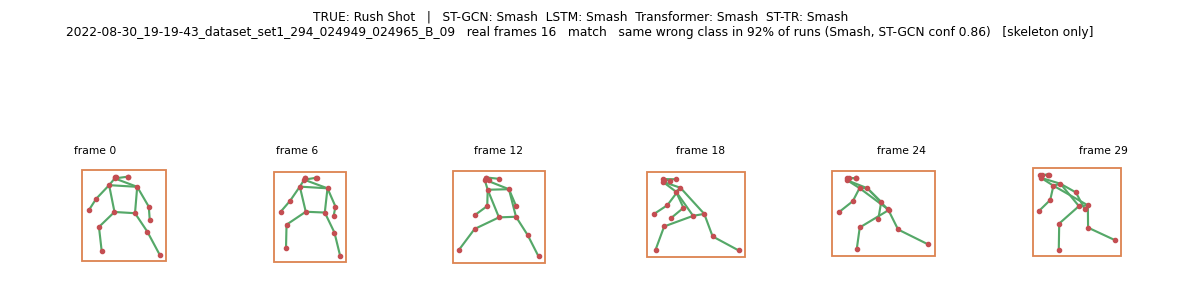

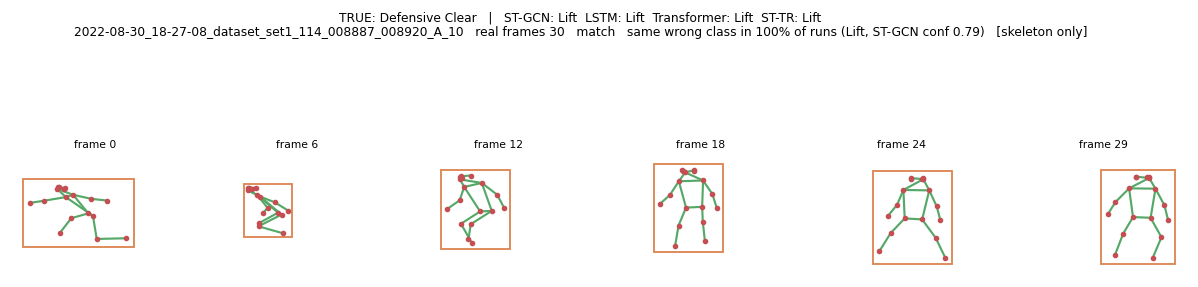

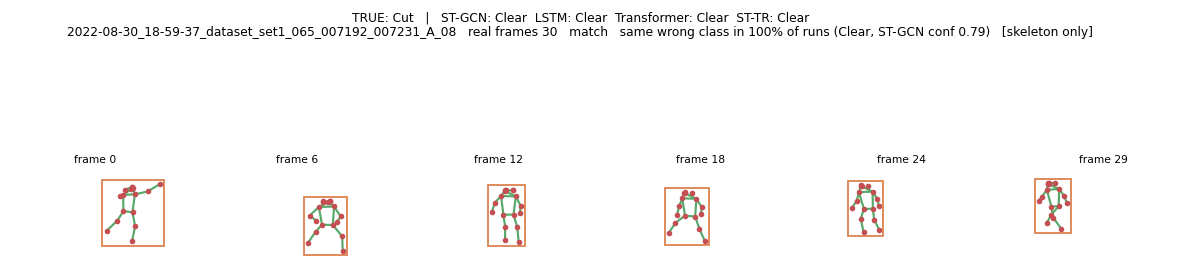

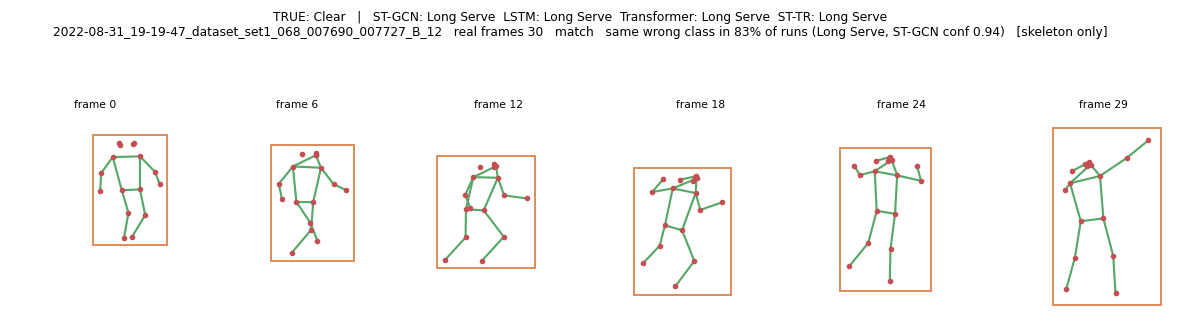

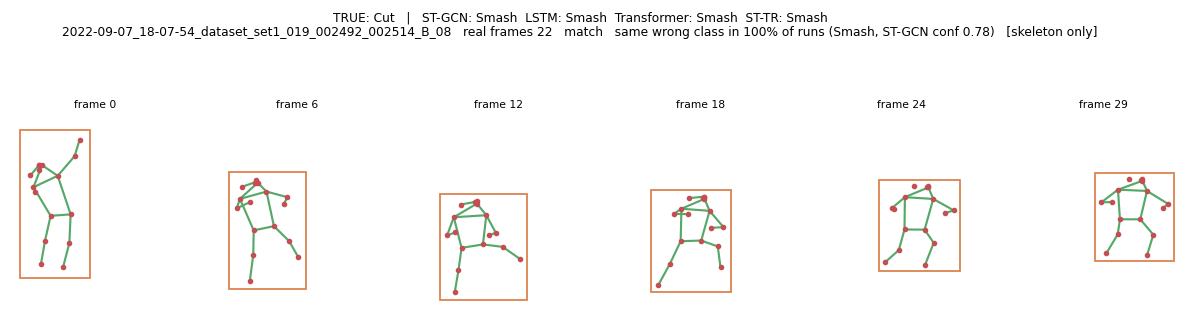

In [8]:
gallery(audit_set, n=8, start=8)

### A specific confusion

Set the pair to look at, for example Push Shot labelled clips that get called Lift. Uses the same audit set.

8 audit clips labelled Push Shot and most often called Lift


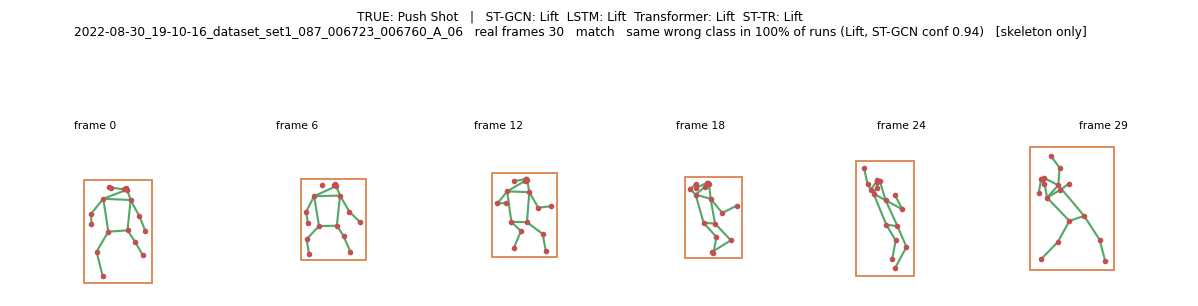

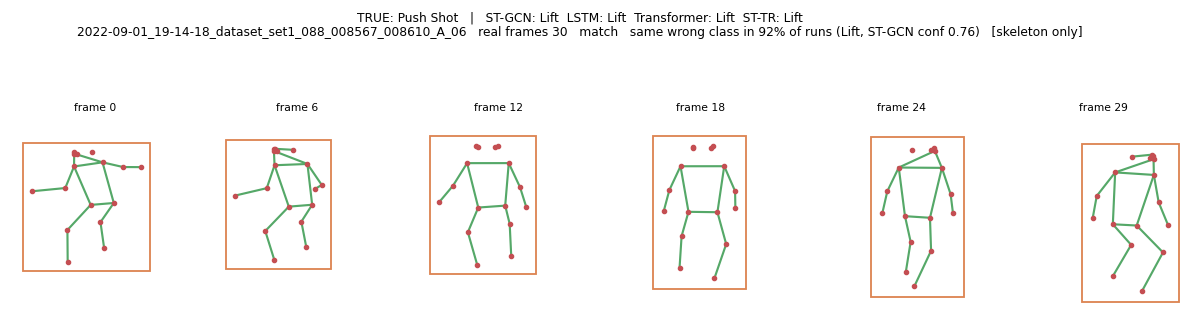

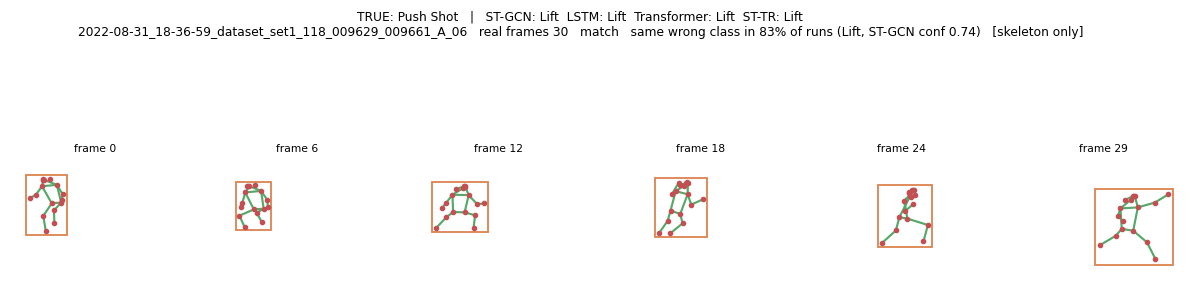

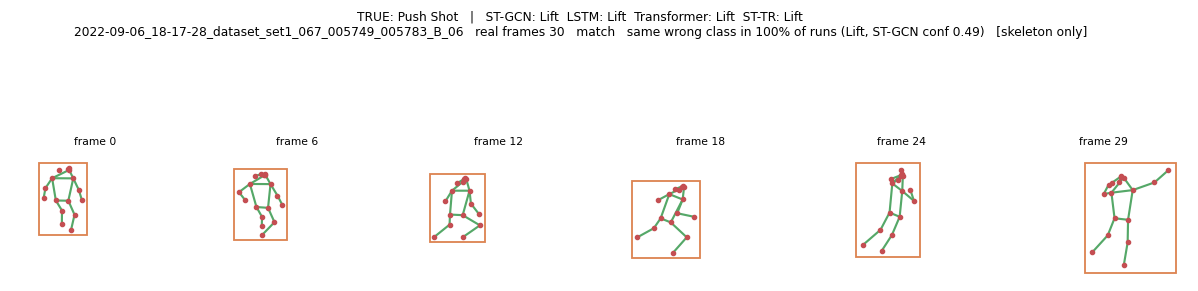

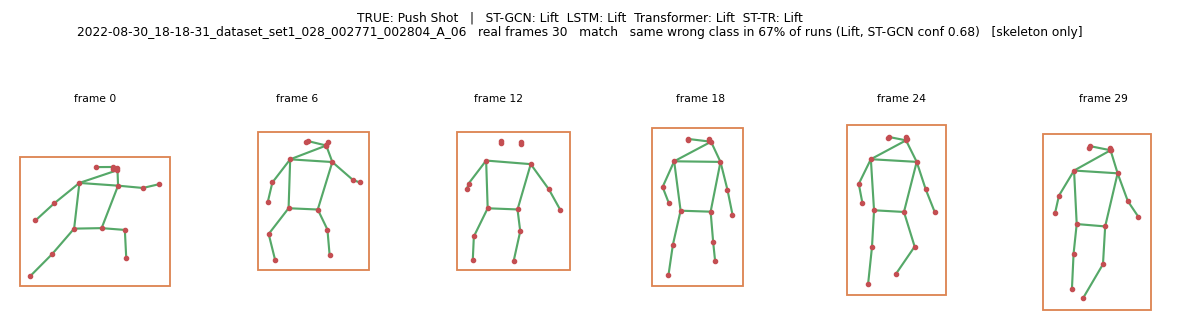

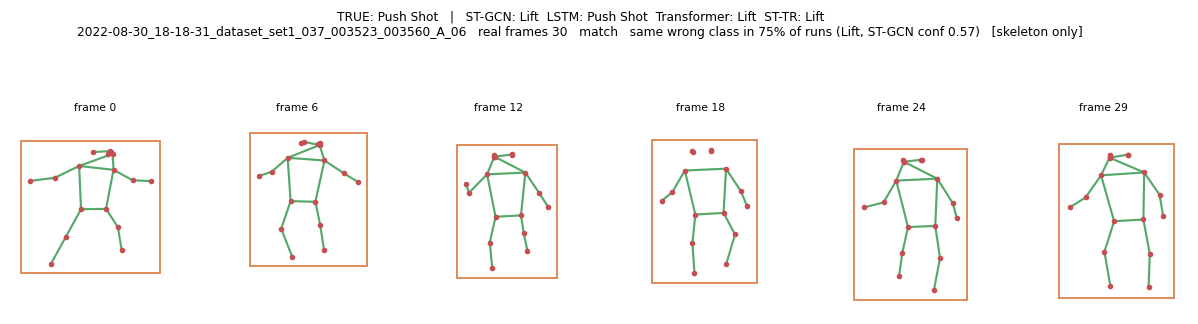

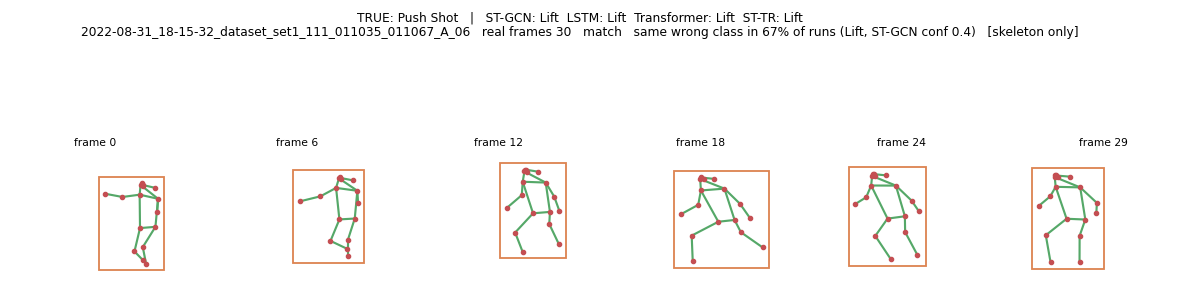

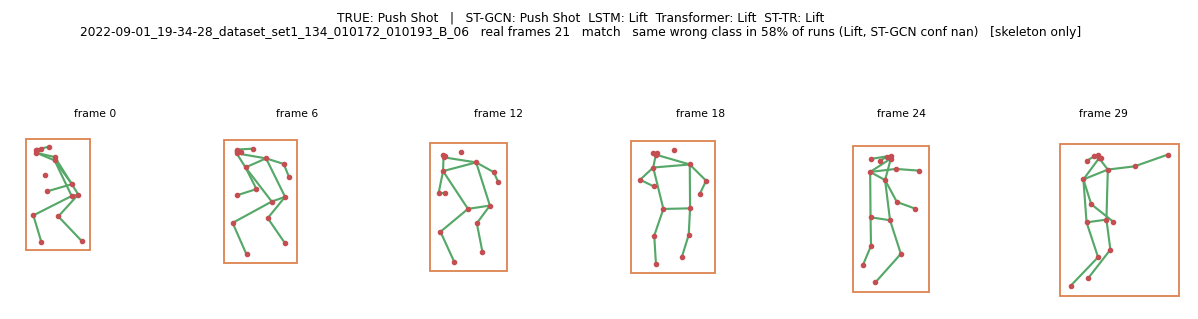

In [9]:
TRUE_CLASS, CALLED = "Push Shot", "Lift"
sub = audit_set[(audit_set["true"] == TRUE_CLASS) & (audit_set["most common wrong class"] == CALLED)]
print(len(sub), f"audit clips labelled {TRUE_CLASS} and most often called {CALLED}")
gallery(sub, n=8)

### Very short clips

Source clips with only a few real frames cannot contain a whole shot; they are a data problem rather than a model problem.

4 audit clips with fewer than 10 real frames


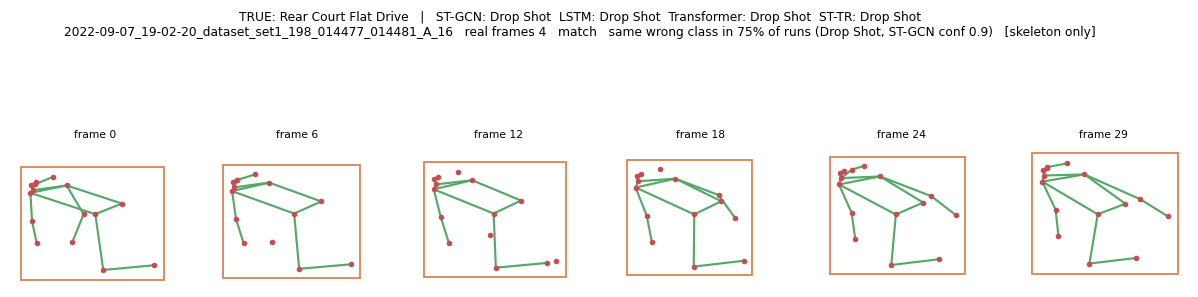

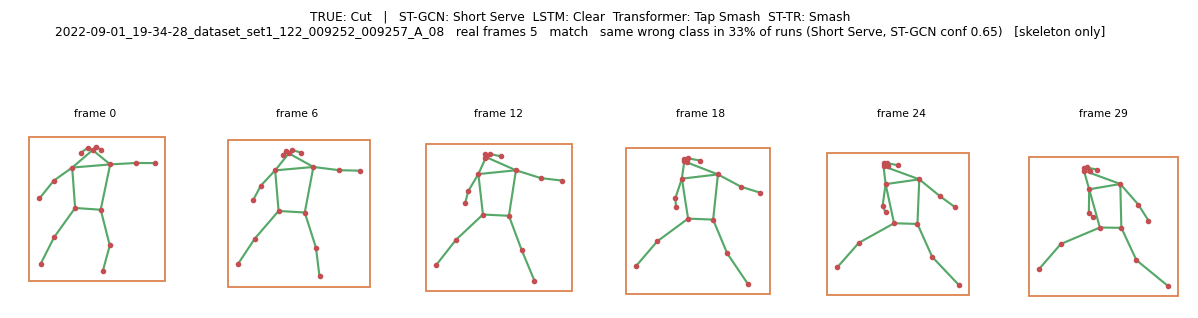

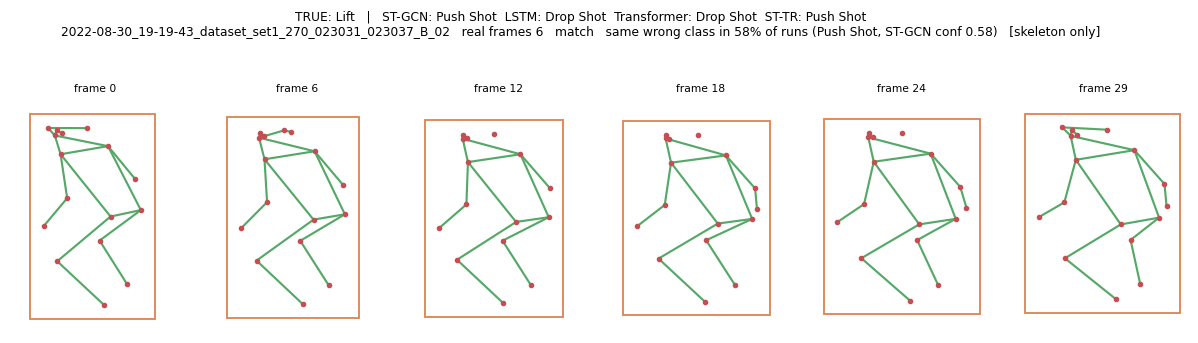

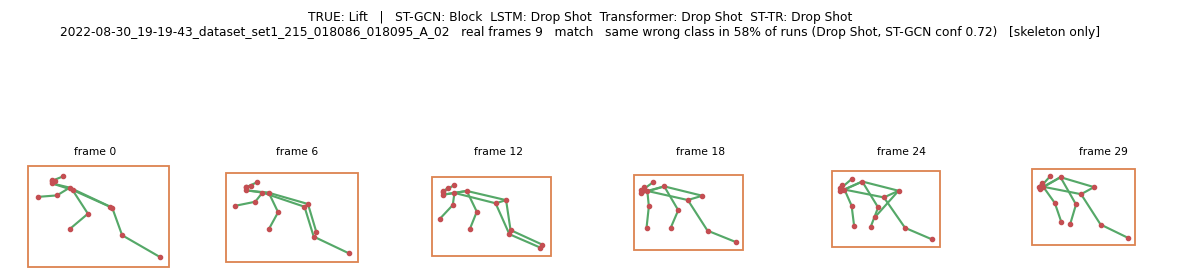

In [10]:
short_clips = audit_set[audit_set["real frames"] < 10].sort_values("real frames")
print(len(short_clips), "audit clips with fewer than 10 real frames")
gallery(short_clips, n=6)

## Recording what you see

The CSV below has one row per audit clip and an empty `verdict` column. Fill it in while looking at the galleries (suggested values: `label ok`, `label wrong`, `ambiguous`, `wrong player`, `bad clip`, `hit not in clip`),
save it, then run the last cell to count the verdicts. A few dozen verdicts are enough to say whether label noise is a material part of the ceiling.

In [11]:
verdict_path = f"{EXPORT}/error_audit_verdicts.csv"
export = audit_set.reset_index().rename(columns={"index": "filepath"})
if os.path.exists(verdict_path):
    old = pd.read_csv(verdict_path)
    export = export.merge(old[[c for c in ("filepath", "verdict", "note") if c in old.columns]], on="filepath", how="left")
else:
    export["verdict"], export["note"] = "", ""
export.to_csv(verdict_path, index=False)
task.upload_artifact("audit_set", artifact_object=verdict_path)
print("written", verdict_path, "(edit the verdict column, keep the file name)")

written /workspace/outputs/results/error_audit_verdicts.csv (edit the verdict column, keep the file name)


In [12]:
v = pd.read_csv(verdict_path)
done = v[v["verdict"].notna() & (v["verdict"].astype(str).str.strip() != "")]
if len(done) == 0:
    print("no verdicts recorded yet")
else:
    counts = done["verdict"].value_counts().rename("clips").to_frame()
    counts["share of reviewed (%)"] = (100 * counts["clips"] / len(done)).round(1)
    print(f"{len(done)} of {len(v)} audit clips reviewed")
    logger.report_table("audit verdicts", "error_audit", iteration=0, table_plot=counts.reset_index().rename(columns={"index": "verdict"}))
    print(counts.to_string())

no verdicts recorded yet


## How to read this

- **Mostly `label ok` and `ambiguous`:** the clips are fine and the shots genuinely look alike from the body alone, which supports the input ceiling reading and the call for more than body keypoints.
- **A real share of `label wrong`, `wrong player`, `bad clip` or `hit not in clip`:** part of the ceiling is data quality, which is a finding in itself and a legitimate target for validation based fixes (noise robust loss, relabelling, dropping unusable clips from training). The count, not any single clip, is the result.
- **Do not tune on these test clips.** Use the audit to decide what to try; evaluate any fix on validation and report on test once.